In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = {
    'Hours_Studied': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                      11, 12, 13, 14, 15],

    'Marks': [35, 40, 45, 50, 54, 60, 65, 70, 75, 80,
              84, 88, 91, 94, 97]
}

df = pd.DataFrame(data)

df

,Hours_Studied,Marks
0,1,35
1,2,40
2,3,45
3,4,50
4,5,54
5,6,60
6,7,65
7,8,70
8,9,75
9,10,80


In [3]:
X = df[['Hours_Studied']]
y = df['Marks']

print("Independent Variable: Hours Studied")
print("Dependent Variable: Marks")

Independent Variable: Hours Studied
Dependent Variable: Marks


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 12
Testing samples: 3


In [5]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)

y_train_scaled = scaler_y.fit_transform(
    y_train.values.reshape(-1, 1)
).ravel()

X_test_scaled = scaler_X.transform(X_test)

In [6]:
svr = SVR(
    kernel='rbf',
    C=100,
    gamma='scale',
    epsilon=0.1
)

svr.fit(X_train_scaled, y_train_scaled)

print("SVR model trained successfully.")

SVR model trained successfully.


In [7]:
y_pred_scaled = svr.predict(X_test_scaled)

y_pred = scaler_y.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

print("Actual Marks:")
print(y_test.values)

print("\nPredicted Marks:")
print(y_pred)

Actual Marks:
[80 88 35]

Predicted Marks:
[77.6323997  86.90466536 43.21757065]


In [8]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 24.777918844101023


In [9]:
r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: 0.954470953532685


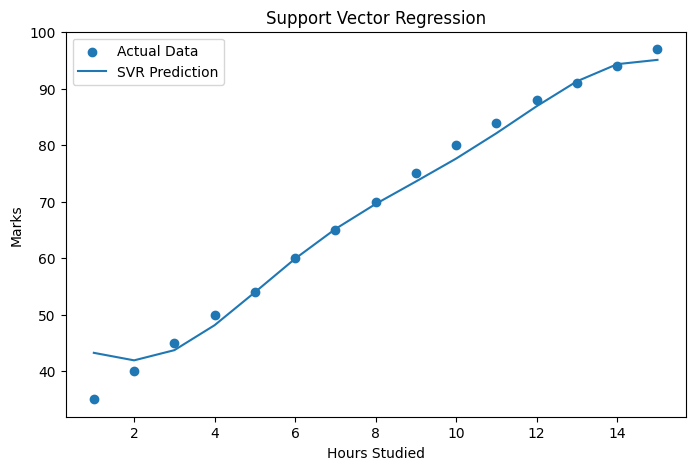

In [10]:
X_all_scaled = scaler_X.transform(X)

y_all_pred_scaled = svr.predict(X_all_scaled)

y_all_pred = scaler_y.inverse_transform(
    y_all_pred_scaled.reshape(-1, 1)
).ravel()

plt.figure(figsize=(8, 5))

plt.scatter(
    X['Hours_Studied'],
    y,
    label='Actual Data'
)

plt.plot(
    X['Hours_Studied'],
    y_all_pred,
    label='SVR Prediction'
)

plt.xlabel('Hours Studied')
plt.ylabel('Marks')
plt.title('Support Vector Regression')
plt.legend()

plt.show()

In [11]:
new_student = pd.DataFrame({
    'Hours_Studied': [10.5]
})

new_student_scaled = scaler_X.transform(new_student)

prediction_scaled = svr.predict(new_student_scaled)

prediction = scaler_y.inverse_transform(
    prediction_scaled.reshape(-1, 1)
).ravel()

print("Hours Studied:", 10.5)
print("Predicted Marks:", prediction[0])

Hours Studied: 10.5
Predicted Marks: 79.81833940640149
